# Etapa 3 — Modelagem

Entrada: `../data/processed/dataset.csv`, da Etapa 2.
Saída: um classificador treinado, avaliado e interpretado, e um ranking dos
melhores horários da janela.

Um detalhe que define esta etapa: **não existe label pronta.** O site
classifica as condições para pesca, não para surf — e pesca gosta de mar
calmo, quase o oposto. Definir o que é uma condição boa para surfar é a
primeira tarefa aqui, e é uma decisão sua.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score, recall_score
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
SEMENTE = 42

## 1. Carregar o dataset processado

Confira que veio o que você espera: número de linhas, tipos, nulos. Se a
Etapa 2 mudou, isso aparece aqui.

In [2]:
dataset = pd.read_csv(DIR_PROC / "dataset.csv", parse_dates=["datetime"])
print(dataset.shape, "| nulos:", dataset.isna().sum().sum())
print(dataset.dtypes.astype(str).to_dict())
dataset.head(3)

(168, 11) | nulos: 0
{'datetime': 'datetime64[us]', 'data': 'str', 'hora': 'int64', 'onda_m': 'float64', 'onda_dir': 'str', 'vento_kmh': 'float64', 'vento_dir': 'str', 'mare_m': 'float64', 'mare_subindo': 'int64', 'coeficiente': 'float64', 'lua_idade': 'int64'}


,datetime,data,hora,onda_m,onda_dir,vento_kmh,vento_dir,mare_m,mare_subindo,coeficiente,lua_idade
0,2026-10-10 00:00:00,2026-10-10,0,0.9,ESE,24.0,ESE,1.219251,1,96.0,29
1,2026-10-10 01:00:00,2026-10-10,1,1.0,ESE,25.0,SE,1.814631,1,96.0,29
2,2026-10-10 02:00:00,2026-10-10,2,1.0,ESE,24.0,SE,2.306899,1,96.0,29


## 2. Definir a label

Escreva, em código, a regra que separa condições ruins, boas e ótimas (ou
outro conjunto de classes, se preferir).

- Quais variáveis entram na regra: altura da onda, vento, maré, direção?
- Quais limiares? De onde vem o número — leitura, conversa com surfista,
  distribuição dos próprios dados? Registre a origem, mesmo que seja um chute
  informado.
- Como as classes ficaram distribuídas? Se 95% das horas caírem numa classe,
  a métrica do modelo vai mentir para você.

Documente a regra em markdown antes de seguir. Tudo depois disso depende dela.

### Regra de label (Passo 5)

Três classes: **ruim**, **boa** e **ótima**. Todos os números abaixo são chutes meus. Não validei nada com dados reais de surf.

| Classe | Regra |
|---|---|
| **ótima** | onda ≥ 1,3 m **e** vento ≤ 20 km/h **e** maré média |
| **boa** | onda ≥ 1,1 m **e** vento ≤ 24 km/h (e não é ótima) |
| **ruim** | todo o resto |

**De onde vem cada número**

- **Onda (1,1 e 1,3 m):** chute. A onda nesta semana só vai de 0,9 a 1,4 m, de 0,1 em 0,1. Escolhi cortes dentro dessa faixa, porque fora dela uma classe ficaria vazia.
- **Vento (24 e 20 km/h):** chute, partindo da ideia de que vento forte bagunça o mar. Fiquei perto da mediana (22) e do terceiro quartil (24) do vento, para as classes não ficarem vazias.
- **Maré média (35% a 75% da amplitude):** guias gerais de surf dizem que praias de areia funcionam melhor com maré média ([Breakfinder](https://breakfinder.surf/blog/tide-window-optimizer-surf-break-type-guide), [Pacific Surf](https://www.pacificsurf.com/best-tide-for-surfing/)). Para Cabo Branco, uma fonte de viagem fraca ([TripBase](https://www.tripbase.com/destinations/joao-pessoa-brazil/surf/)) diz o mesmo. Usei a amplitude do ano de 2025 (0,0 a 2,8 m), que dá maré média entre 0,98 e 2,10 m. Uso porcentagem e não metros, porque a maré ideal depende do pico.

**O que deixei de fora**

- **Direção do vento:** nas 168 horas ele vem do mar para a costa (ENE a SE; a costa de João Pessoa olha para o leste, ~94°). Como não muda, não separa as classes.
- **Coeficiente e lua:** só 7 valores na semana.

**Duas regras:** a **A** (só onda e vento) fica como referência, e a **D** (com maré) é a label que uso. Comparar as duas mostra o que a maré muda.

**Limitação:** exigir maré média reduz as horas "ótima" de 30 para 14. A classe fica pequena (8%, em 3 dias), o que deixa a avaliação do modelo instável.

In [3]:
ONDA_BOA, ONDA_OTIMA = 1.1, 1.3
VENTO_BOM, VENTO_OTIMO = 24, 20
FASE_MEDIA = (0.35, 0.75)

altura_tabua = pd.read_csv(DIR_RAW / "mares_2025.csv")["altura_m"]
MARE_MIN, MARE_MAX = altura_tabua.min(), altura_tabua.max()
print(f"amplitude da maré na tábua: {MARE_MIN} a {MARE_MAX} m")
print(f"maré média = {MARE_MIN + FASE_MEDIA[0] * (MARE_MAX - MARE_MIN):.2f} a "
      f"{MARE_MIN + FASE_MEDIA[1] * (MARE_MAX - MARE_MIN):.2f} m")


def label_a(linha):
    """Regra A (referência): só onda e vento."""
    if linha["onda_m"] >= ONDA_OTIMA and linha["vento_kmh"] <= VENTO_OTIMO:
        return "otima"
    if linha["onda_m"] >= ONDA_BOA and linha["vento_kmh"] <= VENTO_BOM:
        return "boa"
    return "ruim"


def label_d(linha):
    """Regra D (principal): como A, mas 'ótima' exige maré média; fora dela vira 'boa'."""
    classe = label_a(linha)
    if classe == "otima" and not linha["mare_media"]:
        return "boa"
    return classe


dataset["fase_mare"] = (dataset["mare_m"] - MARE_MIN) / (MARE_MAX - MARE_MIN)
dataset["mare_media"] = dataset["fase_mare"].between(*FASE_MEDIA)
dataset["label_a"] = dataset.apply(label_a, axis=1)
dataset["label"] = dataset.apply(label_d, axis=1)

amplitude da maré na tábua: 0.0 a 2.8 m
maré média = 0.98 a 2.10 m


In [4]:
ordem = ["ruim", "boa", "otima"]
dist = pd.DataFrame({
    "regra A (onda+vento)": dataset["label_a"].value_counts(),
    "regra D (+ maré média)": dataset["label"].value_counts(),
}).loc[ordem]
dist["% da D"] = (100 * dist["regra D (+ maré média)"] / len(dataset)).round(1)
print(dist)

print("\nHoras que mudaram de classe da A para a D:")
print(pd.crosstab(dataset["label_a"], dataset["label"]))

print("\nHoras 'ótima' por dia (regra D):")
print(dataset[dataset["label"] == "otima"].groupby("data").size())

       regra A (onda+vento)  regra D (+ maré média)  % da D
ruim                     61                      61    36.3
boa                      77                      93    55.4
otima                    30                      14     8.3

Horas que mudaram de classe da A para a D:
label    boa  otima  ruim
label_a                  
boa       77      0     0
otima     16     14     0
ruim       0      0    61

Horas 'ótima' por dia (regra D):
data
2026-10-14    5
2026-10-15    8
2026-10-16    1
dtype: int64


## 3. Features e alvo

Separe `X` e `y`.

- Quais colunas entram como feature? Cuidado: usar diretamente as variáveis da
  sua regra faz o modelo apenas redescobrir o `if` que você escreveu. Isso é
  esperado aqui — mas você precisa saber que é isso que está acontecendo.
- Direção do vento e da onda são texto. Como transformar em número sem inventar
  uma ordem que não existe?

In [5]:
numericas = ["onda_m", "vento_kmh", "mare_m", "mare_subindo", "hora"]

X = pd.concat(
    [
        dataset[numericas],
        pd.get_dummies(dataset["onda_dir"], prefix="onda_dir", dtype=int),
        pd.get_dummies(dataset["vento_dir"], prefix="vento_dir", dtype=int),
    ],
    axis=1,
)
y = dataset["label"]
print(X.shape, "| colunas:", list(X.columns))

(168, 11) | colunas: ['onda_m', 'vento_kmh', 'mare_m', 'mare_subindo', 'hora', 'onda_dir_E', 'onda_dir_ESE', 'vento_dir_E', 'vento_dir_ENE', 'vento_dir_ESE', 'vento_dir_SE']


**Escolha das features**

- **Entram:** `onda_m`, `vento_kmh` e `mare_m` (as variáveis da regra; o modelo redescobrir o `if` é esperado), `mare_subindo` e `hora` (que não estão na regra, então um modelo que só copia a regra deve ignorá-las) e as direções.
- **Direção em one-hot:** se eu trocasse E, ESE e SE por 1, 2 e 3, criaria uma ordem que não existe. O one-hot dá uma coluna 0/1 para cada direção.
- **Ficam de fora:** `coeficiente` e `lua_idade` (só 7 valores, um por dia: o modelo decoraria o dia), `data` e `datetime` (mesmo motivo) e as colunas que vêm da regra (`label_a`, `mare_media`, `fase_mare`), que entregariam a resposta.

## 4. Treino e teste

Divida os dados. Vale estratificar pelas classes? A ordem temporal importa —
sortear linhas de um mesmo dia entre treino e teste vaza informação?

In [6]:
grupos = dataset["data"]
cv = LeaveOneGroupOut()
for dia, (tr, te) in zip(sorted(grupos.unique()), cv.split(X, y, grupos)):
    print(dia, "| ótimas no teste:", (y.iloc[te] == "otima").sum(), "| ótimas no treino:", (y.iloc[tr] == "otima").sum())

2026-10-10 | ótimas no teste: 0 | ótimas no treino: 14
2026-10-11 | ótimas no teste: 0 | ótimas no treino: 14
2026-10-12 | ótimas no teste: 0 | ótimas no treino: 14
2026-10-13 | ótimas no teste: 0 | ótimas no treino: 14
2026-10-14 | ótimas no teste: 5 | ótimas no treino: 9
2026-10-15 | ótimas no teste: 8 | ótimas no treino: 6
2026-10-16 | ótimas no teste: 1 | ótimas no treino: 13


**Por que deixar um dia de fora, e não sortear linhas:** as 24 horas de um mesmo dia são quase iguais. Se parte do dia fosse para o treino e parte para o teste, o modelo reconheceria o dia e o resultado ficaria bom demais. Por isso deixo um dia inteiro de fora por vez. O custo é que, com só 7 dias, não dá para estratificar por classe. A "ótima" não aparece em 4 das 7 rodadas (dias 10 a 13). Só as rodadas de 14, 15 e 16/out testam de verdade essa classe.

## 5. Treinar

Treine pelo menos dois modelos de famílias diferentes (por exemplo uma árvore
e um modelo baseado em distância) para ter com o que comparar.

In [7]:
modelos = {
    "baseline (classe mais comum)": DummyClassifier(strategy="most_frequent"),
    "árvore de decisão": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEMENTE),
    "regressão logística": make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)
    ),
}

In [8]:
previsoes = {nome: cross_val_predict(m, X, y, groups=grupos, cv=cv) for nome, m in modelos.items()}

**Sobre o treino:** a árvore tem `max_depth=4`, para ficar fácil de ler (não testei outros valores). Usei `class_weight="balanced"` para a classe "ótima", que é rara, pesar mais. Sem isso o modelo teria pouco motivo para acertá-la. Não fiz busca de hiperparâmetros: com 7 dias isso só ajustaria o modelo ao acaso.

## 6. Avaliar

- Acurácia é suficiente aqui, com as classes desbalanceadas como estão?
- Olhe a matriz de confusão: que erro o modelo comete?
- Um único split é confiável com poucas linhas, ou vale validação cruzada?

In [9]:
ordem = ["ruim", "boa", "otima"]
linhas = []
for nome, pred in previsoes.items():
    linhas.append({
        "modelo": nome,
        "acurácia": (pred == y).mean(),
        "F1 macro": f1_score(y, pred, average="macro", labels=ordem, zero_division=0),
        "recall ótima": recall_score(y, pred, labels=["otima"], average=None, zero_division=0)[0],
        "F1 ótima": f1_score(y, pred, labels=["otima"], average=None, zero_division=0)[0],
    })
resumo = pd.DataFrame(linhas).set_index("modelo").round(2)
print(resumo)
print()
print(classification_report(y, previsoes["árvore de decisão"], labels=ordem, zero_division=0))

                              acurácia  F1 macro  recall ótima  F1 ótima
modelo                                                                  
baseline (classe mais comum)      0.55      0.24          0.00      0.00
árvore de decisão                 0.93      0.90          0.86      0.83
regressão logística               0.74      0.69          0.79      0.50

              precision    recall  f1-score   support

        ruim       0.90      1.00      0.95        61
         boa       0.98      0.89      0.93        93
       otima       0.80      0.86      0.83        14

    accuracy                           0.93       168
   macro avg       0.89      0.92      0.90       168
weighted avg       0.93      0.93      0.93       168



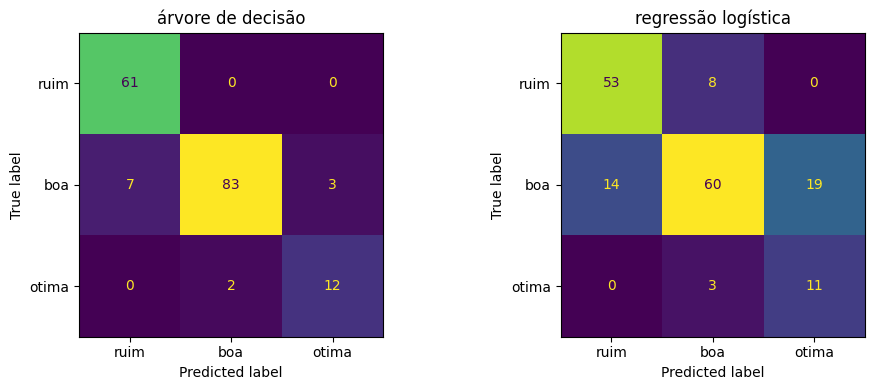

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, nome in zip(axs, ["árvore de decisão", "regressão logística"]):
    ConfusionMatrixDisplay.from_predictions(y, previsoes[nome], labels=ordem, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

**Leitura da avaliação (deixando um dia de fora por vez)**

| Modelo | Acurácia | F1 macro | Recall "ótima" | F1 "ótima" |
|---|---|---|---|---|
| Baseline (classe mais comum) | 0,55 | 0,24 | 0,00 | 0,00 |
| **Árvore de decisão** | 0,93 | 0,90 | 0,86 | 0,83 |
| Regressão logística | 0,74 | 0,69 | 0,79 | 0,50 |

- **A acurácia sozinha engana:** um modelo que sempre diz "boa" já tem 0,55 e nunca acerta uma "ótima". Por isso olho o recall e o F1 da classe rara (14 horas, 8%).
- **Árvore:** acerta 12 das 14 horas "ótima" em dias que não viu no treino. A precisão é 0,80 (3 horas "boa" foram chamadas de "ótima"). Os erros ficam na borda da faixa de maré média: marés de 2,09 a 2,29 m ou de 1,07 m, onde a regra corta em 2,10 e 0,98 m e os outros dias não tinham exemplos. Ela também chama de "ruim" 7 horas que são "boa", todas em 10/out com onda de exatamente 1,1 m (o limiar da regra). Quase todas as horas de 1,1 m estão nesse dia, então quando ele fica de fora o modelo nunca viu esse valor. É falta de dias, não defeito da árvore.
- **Regressão logística:** acerta 11 das 14 "ótima", mas chama de "ótima" 19 horas que são "boa" (F1 0,50). A regra junta três condições com "e" e uma faixa de maré (nem baixa, nem alta demais). Isso não é uma fronteira reta, e a regressão logística separa mal. Não é que ela seja pior, ela só não combina com esta regra.
- **Limite:** a "ótima" só existe em 3 dos 7 dias (14 linhas). A diferença entre recall 0,86 e 0,79 é de 1 hora, então não leio isso como diferença real.

## 7. Interpretar

Um modelo que acerta e você não sabe por quê não serve para responder nada.

- Plote a árvore. Os cortes que ela encontrou parecem com os seus limiares?
- Quais features o modelo considera mais importantes? Bate com sua intuição?
- Se a acurácia veio altíssima, explique o motivo — não celebre.

|--- vento_kmh <= 20.50
|   |--- mare_m <= 1.07
|   |   |--- class: boa
|   |--- mare_m >  1.07
|   |   |--- onda_m <= 1.25
|   |   |   |--- class: boa
|   |   |--- onda_m >  1.25
|   |   |   |--- mare_m <= 2.11
|   |   |   |   |--- class: otima
|   |   |   |--- mare_m >  2.11
|   |   |   |   |--- class: boa
|--- vento_kmh >  20.50
|   |--- onda_m <= 1.05
|   |   |--- class: ruim
|   |--- onda_m >  1.05
|   |   |--- vento_kmh <= 24.50
|   |   |   |--- class: boa
|   |   |--- vento_kmh >  24.50
|   |   |   |--- vento_dir_E <= 0.50
|   |   |   |   |--- class: ruim
|   |   |   |--- vento_dir_E >  0.50
|   |   |   |   |--- class: ruim



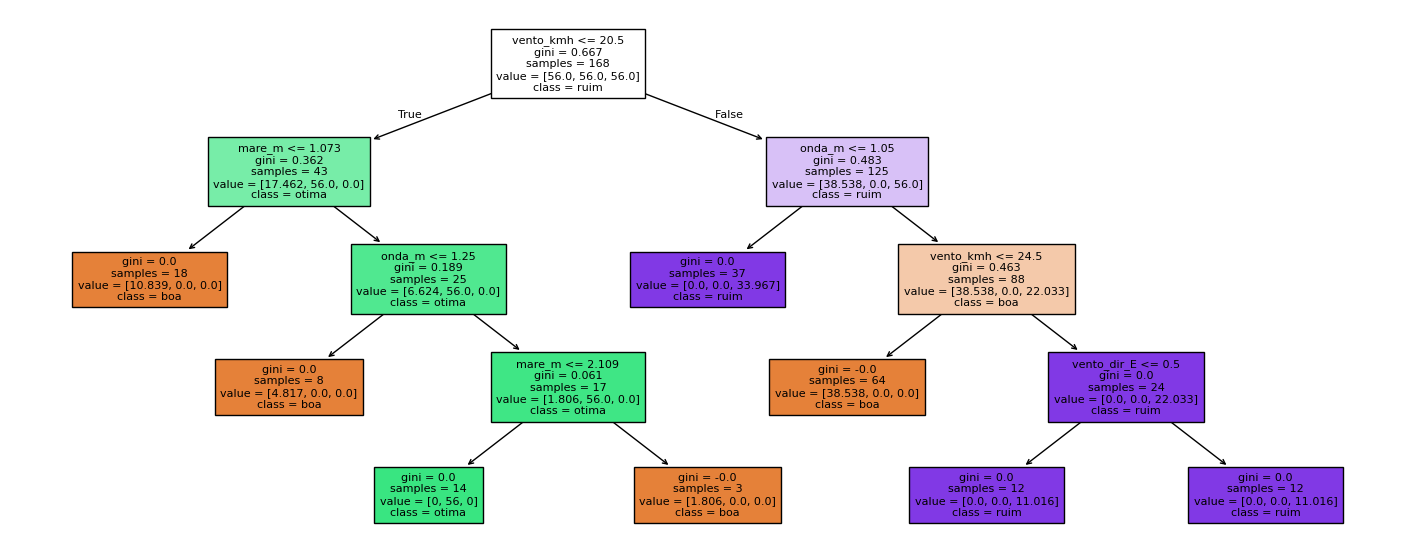

In [11]:
arvore = modelos["árvore de decisão"].fit(X, y)
print(export_text(arvore, feature_names=list(X.columns)))
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arvore, feature_names=list(X.columns), class_names=list(arvore.classes_), filled=True, fontsize=8, ax=ax)
plt.show()

vento_kmh      0.605
onda_m         0.232
mare_m         0.163
vento_dir_E    0.000
dtype: float64


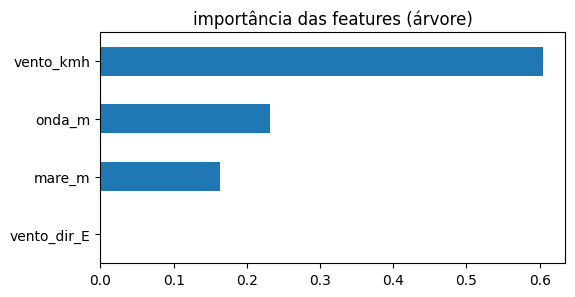

In [12]:
imp = pd.Series(arvore.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp[imp > 0].round(3))
imp[imp > 0].sort_values().plot.barh(figsize=(6, 3), title="importância das features (árvore)")
plt.show()

**Leitura da interpretação**

- **Os cortes da árvore são os da minha regra, um pouco deslocados:** vento ≈ 20,5 (regra: 20), onda ≈ 1,25 (1,3) e ≈ 1,05 (1,1), vento ≈ 24,5 (24) e maré entre 1,07 e 2,11 m (0,98 a 2,10). A árvore recuperou o `if` que escrevi. A diferença vem de ela cortar no meio entre dois valores vizinhos dos dados (a onda vem de 0,1 em 0,1).
- **Importância:** vento 0,61, onda 0,23 e maré 0,16. `hora`, `mare_subindo` e as direções ficaram em ~0. O modelo ignora o que não está na regra, como quem copia uma regra.
- **Um corte sem efeito:** o ramo `vento_dir_E` separa dois ramos que terminam em "ruim", então não muda nenhuma previsão. É sobra de a árvore não ter sido podada.
- **A acurácia de 0,93** não quer dizer que o modelo previu o mar. Ele reaprendeu a minha regra a partir das mesmas variáveis. Mede o quanto uma árvore reproduz um `if` com poucos cortes.

## 8. Responder a pergunta

Aplique o modelo na janela inteira e produza a resposta para Felipe e Nicholas:

- Quais os melhores dias da janela de previsão?
- Em média, qual o melhor horário do dia?
- Em que grau essa resposta é uma previsão do mar, e em que grau é apenas a
  sua regra reescrita?

In [13]:
proba = pd.DataFrame(arvore.predict_proba(X), columns=arvore.classes_, index=dataset.index)
dataset["nota"] = proba["boa"] * 1 + proba["otima"] * 2
dataset["previsto"] = arvore.predict(X)

HORA_LUZ = (5, 17)
dataset["dia_claro"] = dataset["hora"].between(*HORA_LUZ)

ranking = (
    dataset[dataset["dia_claro"]]
    .sort_values(["nota", "onda_m", "vento_kmh"], ascending=[False, False, True])
)
print("Top 10 horas de luz da janela:")
print(ranking[["datetime", "onda_m", "vento_kmh", "mare_m", "previsto", "nota"]].head(10).to_string(index=False, float_format="%.2f"))
print("\nHoras 'ótima' fora da luz (descartadas):", ((dataset["previsto"] == "otima") & ~dataset["dia_claro"]).sum(),
      "de", (dataset["previsto"] == "otima").sum())

Top 10 horas de luz da janela:
           datetime  onda_m  vento_kmh  mare_m previsto  nota
2026-10-15 07:00:00    1.40      15.00    2.09    otima  2.00
2026-10-15 06:00:00    1.40      16.00    1.94    otima  2.00
2026-10-14 17:00:00    1.40      19.00    1.86    otima  2.00
2026-10-15 05:00:00    1.40      19.00    1.63    otima  2.00
2026-10-14 15:00:00    1.40      20.00    1.07    otima  2.00
2026-10-15 08:00:00    1.40      20.00    2.05    otima  2.00
2026-10-15 16:00:00    1.30      18.00    1.26    otima  2.00
2026-10-15 17:00:00    1.30      18.00    1.62    otima  2.00
2026-10-16 12:00:00    1.30      20.00    1.09    otima  2.00
2026-10-14 13:00:00    1.40      19.00    0.61      boa  1.00

Horas 'ótima' fora da luz (descartadas): 5 de 14


            horas_otima  horas_boa_ou_melhor  nota_media  onda_media  \
data                                                                   
2026-10-15            6                   13        1.46        1.33   
2026-10-14            2                   11        1.00        1.37   
2026-10-16            1                   12        1.00        1.27   
2026-10-13            0                   10        0.77        1.23   
2026-10-12            0                    8        0.62        1.22   
2026-10-10            0                    7        0.54        1.07   
2026-10-11            0                    0        0.00        0.99   

            vento_medio  
data                     
2026-10-15        19.00  
2026-10-14        21.23  
2026-10-16        21.38  
2026-10-13        21.31  
2026-10-12        23.69  
2026-10-10        23.00  
2026-10-11        23.69  

Nota média por hora de luz:
hora
5     0.71
6     0.57
7     0.57
8     0.57
9     0.57
10    0.71
11    0.71
12    

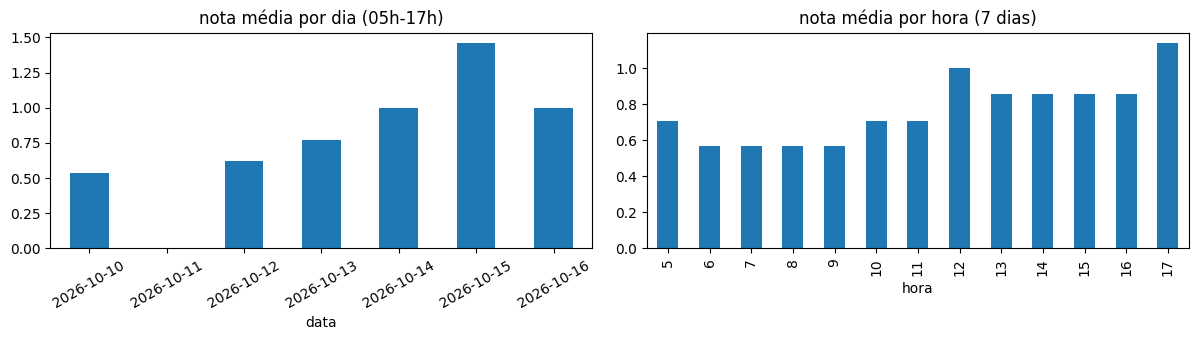

In [14]:
claro = dataset[dataset["dia_claro"]]
por_dia = claro.groupby("data").agg(
    horas_otima=("previsto", lambda s: (s == "otima").sum()),
    horas_boa_ou_melhor=("previsto", lambda s: (s != "ruim").sum()),
    nota_media=("nota", "mean"),
    onda_media=("onda_m", "mean"),
    vento_medio=("vento_kmh", "mean"),
).round(2)
print(por_dia.sort_values("nota_media", ascending=False))

por_hora = claro.groupby("hora")["nota"].mean().round(2)
print("\nNota média por hora de luz:")
print(por_hora.to_string())

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
por_dia["nota_media"].plot.bar(ax=axs[0], title="nota média por dia (05h-17h)", rot=30)
por_hora.plot.bar(ax=axs[1], title="nota média por hora (7 dias)")
plt.tight_layout()
plt.show()

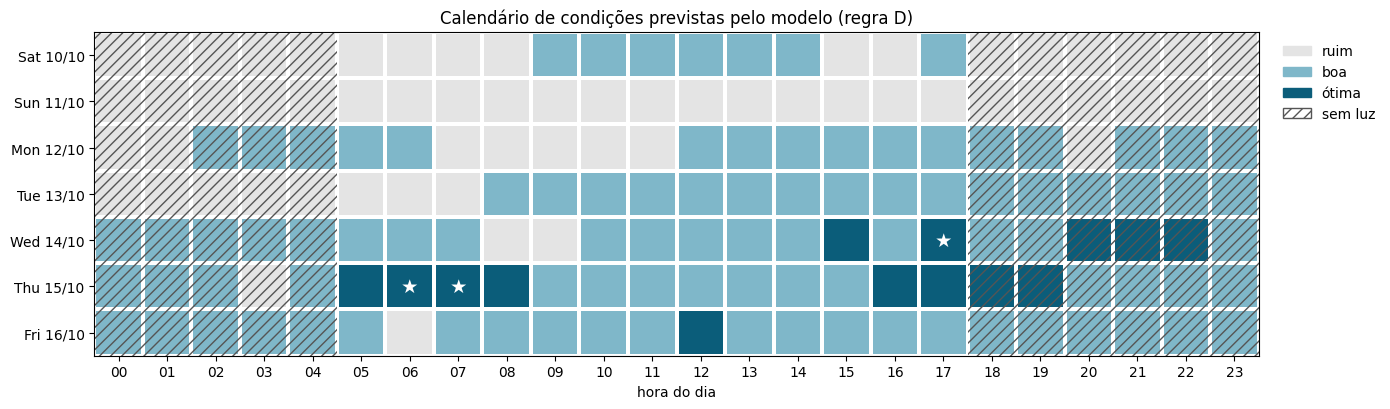

In [15]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle

codigo = {"ruim": 0, "boa": 1, "otima": 2}
cal = dataset.assign(cod=dataset["previsto"].map(codigo)).pivot(index="data", columns="hora", values="cod")
cores = ["#e4e4e4", "#7fb7c9", "#0b5d7a"]

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.pcolormesh(cal.values, cmap=ListedColormap(cores), vmin=-0.5, vmax=2.5, edgecolors="white", linewidth=1.5)
ax.invert_yaxis()
ax.set_xticks(np.arange(24) + 0.5, labels=[f"{h:02d}" for h in range(24)])
ax.set_yticks(np.arange(len(cal)) + 0.5, labels=[pd.Timestamp(d).strftime("%a %d/%m") for d in cal.index])
ax.set(xlabel="hora do dia", title="Calendário de condições previstas pelo modelo (regra D)")

for j, h in enumerate(cal.columns):
    if not (HORA_LUZ[0] <= h <= HORA_LUZ[1]):
        ax.add_patch(Rectangle((j, 0), 1, len(cal), fill=False, hatch="///", edgecolor="#555555", linewidth=0))

for _, r in ranking.head(3).iterrows():
    ax.text(r["hora"] + 0.5, list(cal.index).index(r["data"]) + 0.5, "★", ha="center", va="center", color="white", fontsize=14)

ax.legend(handles=[Patch(color=c, label=n) for c, n in zip(cores, ["ruim", "boa", "ótima"])]
          + [Patch(facecolor="white", edgecolor="#555555", hatch="///", label="sem luz")],
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

**O que li no calendário:**
- A cor escura ("ótima") se concentra em 14 e 15/out. Em 15/out há um bloco de manhã (05h–08h) e outro no fim da tarde (16h–17h). As estrelas são as 3 melhores horas de luz: 15/out às 06h e 07h e 14/out às 17h.
- 10 e 11/out são quase todos cinza ("ruim"). 11/out não tem hora boa, porque a onda fica em ~1,0 m.
- 12 e 13/out são "boa" na maior parte do dia, sem hora "ótima".
- A faixa hachurada são as horas sem luz. O modelo não sabe que é noite (isso não está na label), por isso aparecem horas "ótima" hachuradas em 14/out (20h–22h) e 15/out (18h–19h). Elas não entram no ranking.
- Para usar: escolho o dia pela cor escura e a hora pela coluna sem hachura. Vale só para esta semana, e é a minha regra aplicada à previsão, não uma medição do mar.

**Leitura do ranking**

- **Melhor dia:** 15/out (6 horas "ótima" de luz e nota média 1,46), depois 14/out e 16/out. 10 e 11/out são os piores (onda ≈ 1,0 m; 11/out não tem hora boa).
- **Melhores horas:** as 9 horas "ótima" de luz são 15/out às 05h, 06h, 07h, 08h, 16h e 17h; 14/out às 15h e 17h; e 16/out às 12h. A melhor isolada é 15/out às 07h (onda 1,4 m, vento 15 km/h, maré 2,09 m), seguida de 15/out às 06h.
- **Horário médio:** a nota média é maior às 17h (1,14) e menor entre 6h e 9h (0,57). Mas são só 7 observações por hora, e a maré atrasa cerca de 50 minutos por dia, então o horário "ótimo" por maré muda ao longo da semana. É uma tendência fraca, não uma regra.
- **Filtro de luz:** o modelo não sabe que é noite, e 5 das 14 horas "ótima" caíam fora das horas de luz. Filtrei o ranking para 05h–17h, usando o nascer e o pôr do sol da própria tábua (4:55–4:58 e 17:13–17:14). Decidi isso depois de ver o primeiro ranking, e o filtro fica fora do modelo.
- **Sensibilidade à maré:** 15/out às 07h (onda 1,4 m, vento 15 km/h, o melhor vento da semana) é "ótima" só porque a maré (2,09 m) ficou 0,01 m abaixo do limite da faixa média (2,10 m). Com a amplitude de 3 meses (limite de 1,98 m) ela era "boa". O ranking é sensível a essa fronteira, que vem de uma fonte fraca.
- **Regra e previsão:** o ranking é o `if` que escrevi, reproduzido pela árvore e aplicado à previsão de 7 dias. A árvore está sendo usada nos mesmos dados em que treinou, só para ordenar.

## 9. Conclusão e limites

Em texto:

1. A recomendação, em uma frase.
2. O teto deste modelo: ele reproduz a sua heurística, então é tão bom quanto
   ela. O que faria dela uma regra melhor?
3. O que a janela de ~7 dias e o volume de linhas impedem de afirmar.
4. Como você responderia "qual a melhor época do ano para surfar em João
   Pessoa" — que dado faltaria, e como coletá-lo.

### Conclusão

**1. O que o modelo fez.** Reproduziu a minha regra (acurácia 0,93; recall da "ótima" 0,86). Os cortes da árvore são os meus limiares. Acurácia alta aqui quer dizer que ele decorou o `if`, não que previu o mar.

**2. O limite do modelo.** Ele é no máximo tão bom quanto a regra, e a regra é feita de palpites (limiares de onda e vento e a faixa de maré média). Uma regra melhor precisaria de rótulos reais, como notas de quem surfa, e do pico específico, porque a maré ideal muda de praia para praia.

**3. O que a semana não permite afirmar.** São uns 7 dias independentes e só 14 horas "ótima", então os números são frágeis. Nada vale fora desta semana, nem dá para garantir que o mar siga a previsão.

**4. Melhor época do ano.** Os dados não respondem, porque o site só dá 7 dias à frente. Faltaria uma série histórica de onda e vento, que dá para montar rodando o scraper todo dia por meses.